In [1]:
# ! git clone https://github.com/amazon-science/esci-data.git
# ! cd esci-data
# ! git lfs install
# ! git lfs pull

# Load the shopping queries dataset examples

In [1]:
import pyarrow.parquet as pa

table1 = pa.read_table('esci-data/shopping_queries_dataset/shopping_queries_dataset_examples.parquet')
table1

pyarrow.Table
example_id: int64
query: string
query_id: int64
product_id: string
product_locale: string
esci_label: string
small_version: int64
large_version: int64
split: string
__index_level_0__: int64
----
example_id: [[0,1,2,3,4,...,131067,131068,131069,131070,131071],[131072,131073,131074,131075,131076,...,262139,262140,262141,262142,262143],...,[2359296,2359297,2359298,2359299,2359300,...,2490363,2490364,2490365,2490366,2490367],[2490368,2490369,2490370,2490371,2490372,...,2621283,2621284,2621285,2621286,2621287]]
query: [[" revent 80 cfm"," revent 80 cfm"," revent 80 cfm"," revent 80 cfm"," revent 80 cfm",...,"90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women"],["90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women","90 degrees jacket women",...,"baby snack containers","baby snack containers","baby snack containers","baby snack containers","baby snack co

In [3]:
df1 = table1.to_pandas()
# Taking tanspose so the printing dataset will easy.
df1.head().T

,0,1,2,3,4
example_id,0,1,2,3,4
query,revent 80 cfm,revent 80 cfm,revent 80 cfm,revent 80 cfm,revent 80 cfm
query_id,0,0,0,0,0
product_id,B000MOO21W,B07X3Y6B1V,B07WDM7MQQ,B07RH6Z8KW,B07QJ7WYFQ
product_locale,us,us,us,us,us
esci_label,I,E,E,E,E
small_version,0,0,0,0,0
large_version,1,1,1,1,1
split,train,train,train,train,train


In [4]:
df1.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [5]:
df1.info()

<class 'pandas.DataFrame'>
Index: 2621288 entries, 0 to 2621287
Data columns (total 9 columns):
 #   Column          Dtype
---  ------          -----
 0   example_id      int64
 1   query           str  
 2   query_id        int64
 3   product_id      str  
 4   product_locale  str  
 5   esci_label      str  
 6   small_version   int64
 7   large_version   int64
 8   split           str  
dtypes: int64(4), str(5)
memory usage: 300.1 MB


In [6]:
df1.describe()

,example_id,query_id,small_version,large_version
count,2.621288e+06,2.621288e+06,2.621288e+06,2621288.0
mean,1.310644e+06,6.632069e+04,4.265121e-01,1.0
std,7.567008e+05,3.883077e+04,4.945701e-01,0.0
min,0.000000e+00,0.000000e+00,0.000000e+00,1.0
25%,6.553218e+05,3.252575e+04,0.000000e+00,1.0
50%,1.310644e+06,6.647900e+04,0.000000e+00,1.0
75%,1.965965e+06,1.006160e+05,1.000000e+00,1.0
max,2.621287e+06,1.306510e+05,1.000000e+00,1.0


In [7]:
df1['split'].value_counts()

split
train    1983272
test      638016
Name: count, dtype: int64

# Load the shopping queries dataset products

In [8]:
import pyarrow.parquet as pa

table2 = pa.read_table('esci-data/shopping_queries_dataset/shopping_queries_dataset_products.parquet')
df2 = table2.to_pandas()
df2.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [9]:
print("EXAMPLES COLUMNS:")
print(df1.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(df2.columns.tolist())

EXAMPLES COLUMNS:
['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split']

PRODUCTS COLUMNS:
['example_id', 'query', 'query_id', 'product_id', 'product_locale', 'esci_label', 'small_version', 'large_version', 'split']


In [10]:
import pandas as pd
from pathlib import Path

# Ελέγχουμε το αρχείο απευθείας από τον δίσκο
path = Path("esci-data/shopping_queries_dataset/shopping_queries_dataset_products.parquet")

print("Αρχείο:", path.resolve())
print("Υπάρχει:", path.exists())

products_check = pd.read_parquet(path)

print("\nShape:", products_check.shape)
print("Columns:", products_check.columns.tolist())

print("\nΠρώτες εγγραφές:")
display(products_check.head(3))

print("\nDuplicate product keys:",
      products_check.duplicated(
          subset=["product_id", "product_locale"]
      ).sum())


Αρχείο: /home/charis/Desktop/Πτυχιακη/Electronics-Recommendation-System/data/esci_data/esci-data/shopping_queries_dataset/shopping_queries_dataset_products.parquet
Υπάρχει: True

Shape: (1814924, 7)
Columns: ['product_id', 'product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color', 'product_locale']

Πρώτες εγγραφές:


,product_id,product_title,product_description,product_bullet_point,product_brand,product_color,product_locale
0,B079VKKJN7,"11 Degrees de los Hombres Playera con Logo, Ne...",Esta playera con el logo de la marca Carrier d...,11 Degrees Negro Playera con logo\nA estrenar ...,11 Degrees,Negro,es
1,B079Y9VRKS,Camiseta Eleven Degrees Core TS White (M),NaN,NaN,11 Degrees,Blanco,es
2,B07DP4LM9H,11 Degrees de los Hombres Core Pull Over Hoodi...,La sudadera con capucha Core Pull Over de 11 G...,11 Degrees Azul Core Pull Over Hoodie\nA estre...,11 Degrees,Azul,es



Duplicate product keys: 0


# Merge the examples with the products

In [11]:
print("EXAMPLES:", df1.shape)
print("PRODUCTS:", df2.shape)

EXAMPLES: (2621288, 9)
PRODUCTS: (2621288, 9)


In [12]:
# Check for duplicate product keys in the products dataset
keys = ["product_id", "product_locale"]

print(
    "\nDuplicate product keys:",
    df2.duplicated(subset=keys).sum()
)

In [13]:
# ΣΗΜΕΙΩΣΗ: το πλήρες merge (όλα τα locales) θέλει πολλή RAM, γι' αυτό έγινε στο Colab (cell 16).
# Η αναπαράξιμη εκδοχή (φίλτρο small/us πριν το merge) είναι το src/data.py:
#   python -m src.data --config configs/data.yaml

# df_examples_products = df1.merge(
#     df2,
#     on=keys,
#     how="left",
#     validate="many_to_one"
# )

# print("\nMERGE SUCCESSFUL")
# print("Examples:", len(df1))
# print("Merged:", len(df_examples_products))

# display(
#     df_examples_products[
#         ["query", "product_title", "esci_label"]
#     ].head(10)
# )

In [2]:
# Merge done on google colab and saved as csv file. Now we will read the csv file and check the data.
df_examples_products = pa.read_table('esci-data/shopping_queries_dataset/merged.parquet').to_pandas()
df_examples_products.head()

,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split,product_title,product_description,product_bullet_point,product_brand,product_color
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train,Panasonic FV-20VQ3 WhisperCeiling 190 CFM Ceil...,NaN,WhisperCeiling fans feature a totally enclosed...,Panasonic,White
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train,Homewerks 7141-80 Bathroom Fan Integrated LED ...,NaN,OUTSTANDING PERFORMANCE: This Homewerk's bath ...,Homewerks,80 CFM
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train,Homewerks 7140-80 Bathroom Fan Ceiling Mount E...,NaN,OUTSTANDING PERFORMANCE: This Homewerk's bath ...,Homewerks,White
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train,Delta Electronics RAD80L BreezRadiance 80 CFM ...,This pre-owned or refurbished product has been...,Quiet operation at 1.5 sones\nBuilt-in thermos...,DELTA ELECTRONICS (AMERICAS) LTD.,White
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train,Panasonic FV-08VRE2 Ventilation Fan with Reces...,NaN,The design solution for Fan/light combinations...,Panasonic,White


# EDA on Merged Data

In [3]:
# Number of rows and columns
df_examples_products.shape

(2621288, 14)

In [4]:
# Summary of DataFrame
df_examples_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2621288 entries, 0 to 2621287
Data columns (total 14 columns):
 #   Column                Dtype
---  ------                -----
 0   example_id            int64
 1   query                 str  
 2   query_id              int64
 3   product_id            str  
 4   product_locale        str  
 5   esci_label            str  
 6   small_version         int64
 7   large_version         int64
 8   split                 str  
 9   product_title         str  
 10  product_description   str  
 11  product_bullet_point  str  
 12  product_brand         str  
 13  product_color         str  
dtypes: int64(4), str(10)
memory usage: 3.3 GB


In [6]:
import pandas as pd
# Number of duplicate rows
dvalues = df_examples_products.duplicated().sum()

# Convert into DataFrame
duplicate_df = pd.DataFrame({"metric": ["duplicate_rows"], "count": [dvalues]})

# Display DataFrame
duplicate_df

,metric,count
0,duplicate_rows,0


In [7]:
# Number of unique values per feature
nuniq = df_examples_products.nunique().reset_index()

# Rename column names
nuniq.columns = ["feature", "unique values"]

# Display DataFrame
nuniq

,feature,unique values
0,example_id,2621288
1,query,130193
2,query_id,130652
3,product_id,1802772
4,product_locale,3
5,esci_label,4
6,small_version,2
7,large_version,1
8,split,2
9,product_title,1782220


In [11]:
import numpy as np
# Select categorical and numerical columns
cat_cols = list(df_examples_products.select_dtypes(include=["object"]).columns)
num_cols = list(df_examples_products.select_dtypes(include=[np.number]).columns)

/tmp/ipykernel_29902/154291666.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = list(df_examples_products.select_dtypes(include=["object"]).columns)


In [12]:
# Statistical summary of numerical data
df_examples_products[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
example_id,2621288.0,1310643.50,756700.81,0.0,655321.75,1310643.5,1965965.25,2621287.0
query_id,2621288.0,66320.69,38830.77,0.0,32525.75,66479.0,100616.00,130651.0
small_version,2621288.0,0.43,0.49,0.0,0.00,0.0,1.00,1.0
large_version,2621288.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0


# Univariate analysis of numerical Columns

# ESCI Label Distribution

esci_label
E    1708158
S     574313
C      75652
I     263165
Name: count, dtype: int64

Percentages:
esci_label
E    65.16
S    21.91
C     2.89
I    10.04
Name: count, dtype: float64


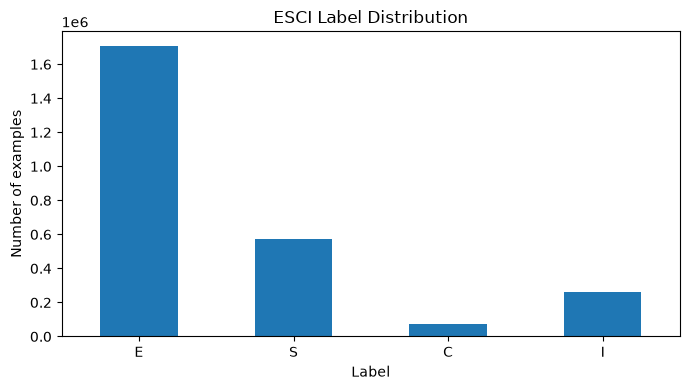

In [15]:
import matplotlib.pyplot as plt

label_counts = (
    df_examples_products["esci_label"]
    .value_counts()
    .reindex(["E", "S", "C", "I"], fill_value=0)
)

print(label_counts)
print("\nPercentages:")
print((label_counts / len(df_examples_products) * 100).round(2))

label_counts.plot(kind="bar", figsize=(7, 4))
plt.title("ESCI Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of examples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Examples per Locale

product_locale
us    1818825
jp     446053
es     356410
Name: count, dtype: int64

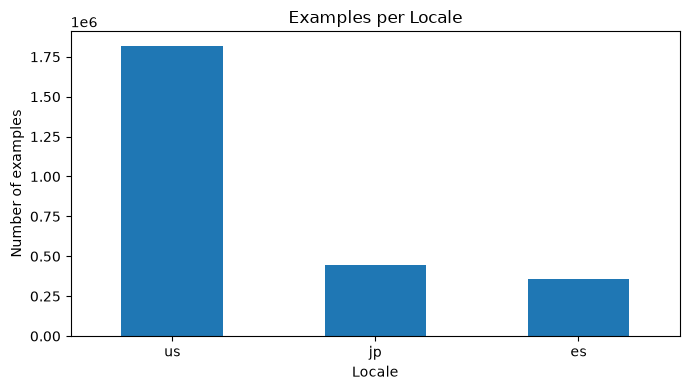

esci_label,C,E,I,S
product_locale,,,,
es,0.058,0.567,0.126,0.250
jp,0.034,0.580,0.127,0.260
us,0.022,0.686,0.089,0.203


In [16]:
locale_counts = df_examples_products["product_locale"].value_counts()

display(locale_counts)

locale_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Examples per Locale")
plt.xlabel("Locale")
plt.ylabel("Number of examples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    pd.crosstab(
        df_examples_products["product_locale"],
        df_examples_products["esci_label"],
        normalize="index"
    ).round(3)
)


# Missing Data per column

In [ ]:
cols = [
    "query",
    "product_title",
    "product_description",
    "product_bullet_point",
    "product_brand",
    "product_color"
]

missing = pd.DataFrame({
    "missing_count": df_examples_products[cols].isna().sum(),
    "missing_percent": (
        df_examples_products[cols].isna().mean() * 100
    ).round(2)
})

display(missing.sort_values(
    "missing_percent",
    ascending=False
))


,missing_count,missing_percent
product_description,1348674,51.45
product_color,910895,34.75
product_bullet_point,364761,13.92
product_brand,166854,6.37
product_title,0,0.00
query,0,0.00


# Products per query

count    130652.000000
mean         20.063130
std           9.339626
min           8.000000
25%          16.000000
50%          16.000000
75%          16.000000
90%          40.000000
95%          40.000000
99%          48.000000
max         198.000000
dtype: float64


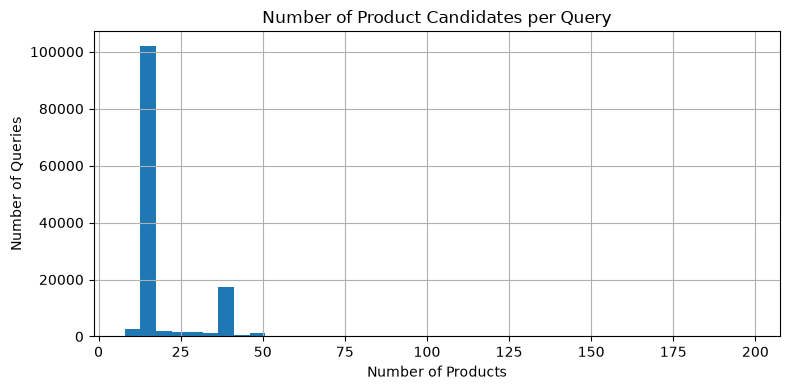

In [19]:
products_per_query = (
    df_examples_products.groupby(["product_locale", "query_id"])
    .size()
)

print(products_per_query.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

products_per_query.hist(
    bins=40,
    figsize=(8, 4)
)

plt.title("Number of Product Candidates per Query")
plt.xlabel("Number of Products")
plt.ylabel("Number of Queries")
plt.tight_layout()
plt.show()
